# Evaluación Sumativa 1: análisis exploratorio e inferencial

**Proyecto:** Análisis estadístico del riesgo de enfermedad coronaria a diez años  
**Dataset:** Framingham Heart Study  
**Estudiante:** Alexander Sepúlveda Ormazábal  
**Asignatura:** MCDI501 — Estadística Computacional para la Toma de Decisiones

Este notebook documenta de manera reproducible la preparación de los datos, el análisis exploratorio,
la estimación de parámetros y las pruebas de hipótesis requeridas en la Fase 2. El análisis es
observacional: los resultados permiten estudiar asociaciones, pero no establecer causalidad.

## Objetivos y criterios cubiertos

1. Verificar estructura, tipos, faltantes, duplicados e inconsistencias.
2. Caracterizar variables numéricas y categóricas mediante medidas y gráficos adecuados.
3. Explorar relaciones bivariadas vinculadas con `TenYearCHD`.
4. Estimar al menos tres medias poblacionales mediante intervalos de confianza del 95 %.
5. Aplicar dos pruebas de hipótesis con supuestos, nivel de significancia y tamaños de efecto.
6. Generar figuras reproducibles para el informe técnico.

Se fija una semilla igual a **42** para asegurar reproducibilidad en cualquier procedimiento aleatorio.

## 0. Configuración reproducible y carga de datos

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportion_confint

warnings.filterwarnings("ignore", category=FutureWarning)

SEMILLA = 42
np.random.seed(SEMILLA)

sns.set_theme(style="whitegrid", context="notebook")
PALETA = {0: "#4C78A8", 1: "#E45756"}


def encontrar_raiz(inicio=None):
    # Busca la raíz del repositorio desde la carpeta de trabajo actual.
    inicio = Path(inicio or Path.cwd()).resolve()
    for candidata in (inicio, *inicio.parents):
        if (candidata / "fase-1" / "datos" / "raw" / "framingham.csv").exists():
            return candidata
    raise FileNotFoundError(
        "No se encontró la raíz del proyecto. Inicie Jupyter dentro de C:\\MCDI501-Framingham."
    )


RAIZ = encontrar_raiz()
RUTA_DATOS = RAIZ / "fase-1" / "datos" / "raw" / "framingham.csv"
DIR_FIGURAS = RAIZ / "fase-2" / "sumativa-1" / "figuras"
DIR_FIGURAS.mkdir(parents=True, exist_ok=True)

print("Raíz del proyecto:", RAIZ)
print("Dataset:", RUTA_DATOS)
print("Semilla:", SEMILLA)

Raíz del proyecto: C:\MCDI501-Framingham
Dataset: C:\MCDI501-Framingham\fase-1\datos\raw\framingham.csv
Semilla: 42


In [2]:
df = pd.read_csv(RUTA_DATOS)

print(f"Filas: {df.shape[0]:,}")
print(f"Columnas: {df.shape[1]}")
display(df.head())

Filas: 4,238
Columnas: 16


,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0


## 1. Preparación y calidad de los datos

El archivo original se conserva sin modificaciones. Todas las revisiones y transformaciones se realizan
sobre una copia en memoria denominada `df_analisis`. La ausencia de datos se documenta y cada análisis
utiliza los casos disponibles para las variables involucradas.

In [3]:
diccionario = pd.DataFrame([
    ("male", "Cualitativa nominal dicotómica", "Sexo: 0 = mujer; 1 = hombre"),
    ("age", "Cuantitativa discreta", "Edad en años"),
    ("education", "Cualitativa ordinal", "Nivel educacional, categorías 1 a 4"),
    ("currentSmoker", "Cualitativa nominal dicotómica", "Tabaquismo actual"),
    ("cigsPerDay", "Cuantitativa discreta", "Cigarrillos consumidos por día"),
    ("BPMeds", "Cualitativa nominal dicotómica", "Uso de antihipertensivos"),
    ("prevalentStroke", "Cualitativa nominal dicotómica", "Antecedente de accidente cerebrovascular"),
    ("prevalentHyp", "Cualitativa nominal dicotómica", "Antecedente de hipertensión"),
    ("diabetes", "Cualitativa nominal dicotómica", "Diabetes"),
    ("totChol", "Cuantitativa continua", "Colesterol total, mg/dL"),
    ("sysBP", "Cuantitativa continua", "Presión arterial sistólica, mmHg"),
    ("diaBP", "Cuantitativa continua", "Presión arterial diastólica, mmHg"),
    ("BMI", "Cuantitativa continua", "Índice de masa corporal"),
    ("heartRate", "Cuantitativa continua", "Frecuencia cardíaca, lpm"),
    ("glucose", "Cuantitativa continua", "Glucosa, mg/dL"),
    ("TenYearCHD", "Cualitativa nominal dicotómica", "Enfermedad coronaria a diez años"),
], columns=["variable", "tipo_estadistico", "descripcion"])

display(diccionario)

,variable,tipo_estadistico,descripcion
0,male,Cualitativa nominal dicotómica,Sexo: 0 = mujer; 1 = hombre
1,age,Cuantitativa discreta,Edad en años
2,education,Cualitativa ordinal,"Nivel educacional, categorías 1 a 4"
3,currentSmoker,Cualitativa nominal dicotómica,Tabaquismo actual
4,cigsPerDay,Cuantitativa discreta,Cigarrillos consumidos por día
5,BPMeds,Cualitativa nominal dicotómica,Uso de antihipertensivos
6,prevalentStroke,Cualitativa nominal dicotómica,Antecedente de accidente cerebrovascular
7,prevalentHyp,Cualitativa nominal dicotómica,Antecedente de hipertensión
8,diabetes,Cualitativa nominal dicotómica,Diabetes
9,totChol,Cuantitativa continua,"Colesterol total, mg/dL"


In [4]:
calidad = pd.DataFrame({
    "tipo_python": df.dtypes.astype(str),
    "no_nulos": df.notna().sum(),
    "faltantes": df.isna().sum(),
    "porcentaje_faltantes": (df.isna().mean() * 100).round(2),
    "valores_unicos": df.nunique(dropna=True),
})

duplicados = int(df.duplicated().sum())
print("Filas duplicadas:", duplicados)
display(calidad)

Filas duplicadas: 0


,tipo_python,no_nulos,faltantes,porcentaje_faltantes,valores_unicos
male,int64,4238,0,0.00,2
age,int64,4238,0,0.00,39
education,float64,4133,105,2.48,4
currentSmoker,int64,4238,0,0.00,2
cigsPerDay,float64,4209,29,0.68,33
BPMeds,float64,4185,53,1.25,2
prevalentStroke,int64,4238,0,0.00,2
prevalentHyp,int64,4238,0,0.00,2
diabetes,int64,4238,0,0.00,2
totChol,float64,4188,50,1.18,248


In [5]:
binarias = [
    "male", "currentSmoker", "BPMeds", "prevalentStroke",
    "prevalentHyp", "diabetes", "TenYearCHD"
]
positivas = ["age", "cigsPerDay", "totChol", "sysBP", "diaBP", "BMI", "heartRate", "glucose"]

inconsistencias = {}
for columna in binarias:
    inconsistencias[f"{columna}: fuera de 0/1"] = int(
        (~df[columna].dropna().isin([0, 1])).sum()
    )

inconsistencias["education: fuera de 1-4"] = int(
    (~df["education"].dropna().isin([1, 2, 3, 4])).sum()
)
for columna in positivas:
    inconsistencias[f"{columna}: valores negativos"] = int((df[columna].dropna() < 0).sum())

reporte_inconsistencias = pd.Series(inconsistencias, name="cantidad").to_frame()
display(reporte_inconsistencias)
print("Total de inconsistencias detectadas:", int(reporte_inconsistencias["cantidad"].sum()))

,cantidad
male: fuera de 0/1,0
currentSmoker: fuera de 0/1,0
BPMeds: fuera de 0/1,0
prevalentStroke: fuera de 0/1,0
prevalentHyp: fuera de 0/1,0
diabetes: fuera de 0/1,0
TenYearCHD: fuera de 0/1,0
education: fuera de 1-4,0
age: valores negativos,0
cigsPerDay: valores negativos,0


Total de inconsistencias detectadas: 0


In [6]:
df_analisis = df.copy()

etiquetas_chd = {0: "No desarrolló CHD", 1: "Desarrolló CHD"}
etiquetas_si_no = {0: "No", 1: "Sí"}

df_analisis["CHD_etiqueta"] = df_analisis["TenYearCHD"].map(etiquetas_chd)
df_analisis["hipertension_etiqueta"] = df_analisis["prevalentHyp"].map(etiquetas_si_no)

print("La copia de análisis fue creada. El archivo original no se modificó.")

La copia de análisis fue creada. El archivo original no se modificó.


**Decisión de preparación.** No se imputan valores ausentes en esta fase porque el porcentaje es bajo en
la mayoría de las variables y los procedimientos pueden declarar su tamaño muestral efectivo. `glucose`
requiere especial cautela por presentar la mayor proporción de ausencia. Las etiquetas agregadas se usan
solo para mejorar la legibilidad de tablas y gráficos.

## 2. Análisis exploratorio de datos

### 2.1 Estadística descriptiva de variables numéricas

In [7]:
variables_numericas = [
    "age", "cigsPerDay", "totChol", "sysBP",
    "diaBP", "BMI", "heartRate", "glucose"
]

resumen_numerico = pd.DataFrame({
    "n": df_analisis[variables_numericas].count(),
    "faltantes": df_analisis[variables_numericas].isna().sum(),
    "media": df_analisis[variables_numericas].mean(),
    "mediana": df_analisis[variables_numericas].median(),
    "desviacion_estandar": df_analisis[variables_numericas].std(ddof=1),
    "q1": df_analisis[variables_numericas].quantile(0.25),
    "q3": df_analisis[variables_numericas].quantile(0.75),
    "ric": df_analisis[variables_numericas].quantile(0.75) - df_analisis[variables_numericas].quantile(0.25),
    "minimo": df_analisis[variables_numericas].min(),
    "maximo": df_analisis[variables_numericas].max(),
    "asimetria": df_analisis[variables_numericas].skew(),
}).round(2)

display(resumen_numerico)

,n,faltantes,media,mediana,desviacion_estandar,q1,q3,ric,minimo,maximo,asimetria
age,4238,0,49.58,49.0,8.57,42.00,56.00,14.00,32.00,70.0,0.23
cigsPerDay,4209,29,9.00,0.0,11.92,0.00,20.00,20.00,0.00,70.0,1.25
totChol,4188,50,236.72,234.0,44.59,206.00,263.00,57.00,107.00,696.0,0.87
sysBP,4238,0,132.35,128.0,22.04,117.00,144.00,27.00,83.50,295.0,1.15
diaBP,4238,0,82.89,82.0,11.91,75.00,89.88,14.88,48.00,142.5,0.71
BMI,4219,19,25.80,25.4,4.08,23.07,28.04,4.97,15.54,56.8,0.98
heartRate,4237,1,75.88,75.0,12.03,68.00,83.00,15.00,44.00,143.0,0.64
glucose,3850,388,81.97,78.0,23.96,71.00,87.00,16.00,40.00,394.0,6.21


### 2.2 Frecuencias de variables categóricas

In [8]:
variables_categoricas = [
    "male", "education", "currentSmoker", "BPMeds",
    "prevalentStroke", "prevalentHyp", "diabetes", "TenYearCHD"
]

tablas = []
for variable in variables_categoricas:
    frecuencias = df_analisis[variable].value_counts(dropna=False).sort_index()
    temporal = pd.DataFrame({
        "variable": variable,
        "categoria": frecuencias.index.astype(str),
        "frecuencia": frecuencias.values,
        "porcentaje": (frecuencias.values / len(df_analisis) * 100).round(2),
    })
    tablas.append(temporal)

resumen_categorico = pd.concat(tablas, ignore_index=True)
display(resumen_categorico)

,variable,categoria,frecuencia,porcentaje
0,male,0,2419,57.08
1,male,1,1819,42.92
2,education,1.0,1720,40.59
3,education,2.0,1253,29.57
4,education,3.0,687,16.21
5,education,4.0,473,11.16
6,education,NaN,105,2.48
7,currentSmoker,0,2144,50.59
8,currentSmoker,1,2094,49.41
9,BPMeds,0.0,4061,95.82


### 2.3 Figura 1. Variable objetivo y datos faltantes

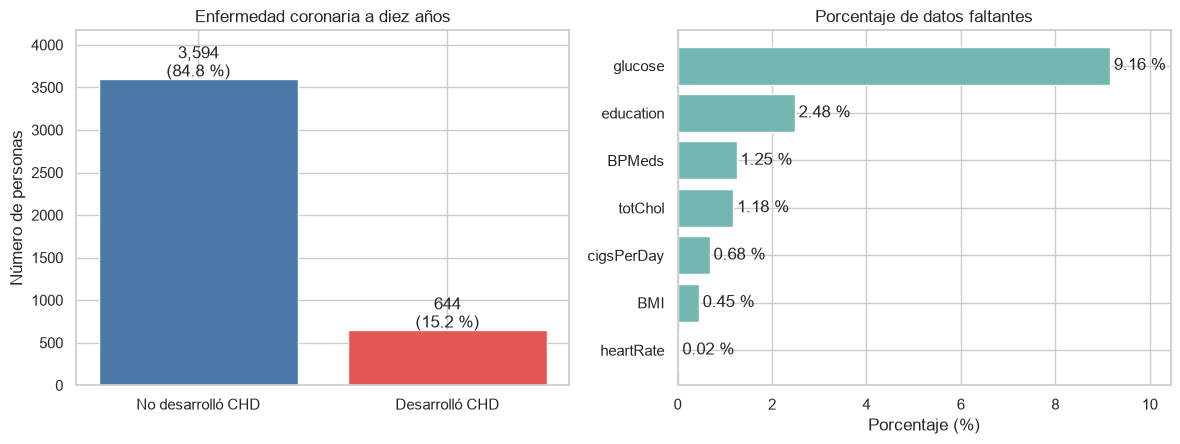

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))

conteos = df_analisis["TenYearCHD"].value_counts().sort_index()
barras = axes[0].bar([etiquetas_chd[i] for i in conteos.index], conteos.values,
                     color=[PALETA[i] for i in conteos.index])
axes[0].set_title("Enfermedad coronaria a diez años")
axes[0].set_ylabel("Número de personas")
axes[0].set_ylim(0, conteos.max() * 1.16)
for barra, valor in zip(barras, conteos.values):
    axes[0].text(barra.get_x() + barra.get_width()/2, valor + 35,
                 f"{valor:,}\n({valor/len(df_analisis)*100:.1f} %)", ha="center")

faltantes = calidad.loc[calidad["faltantes"] > 0, "porcentaje_faltantes"].sort_values()
axes[1].barh(faltantes.index, faltantes.values, color="#72B7B2")
axes[1].set_title("Porcentaje de datos faltantes")
axes[1].set_xlabel("Porcentaje (%)")
axes[1].set_xlim(0, faltantes.max() * 1.14)
for i, valor in enumerate(faltantes.values):
    axes[1].text(valor + 0.08, i, f"{valor:.2f} %", va="center")

plt.tight_layout()
plt.savefig(DIR_FIGURAS / "figura_1_objetivo_faltantes.png", dpi=300, bbox_inches="tight")
plt.show()

La variable de respuesta está desbalanceada: el grupo que desarrolló enfermedad coronaria es menor que
el grupo sin evento. La ausencia de datos se concentra principalmente en glucosa; por ello, los tamaños
muestrales efectivos deben informarse en cada estimación.

### 2.4 Figura 2. Distribuciones de variables numéricas

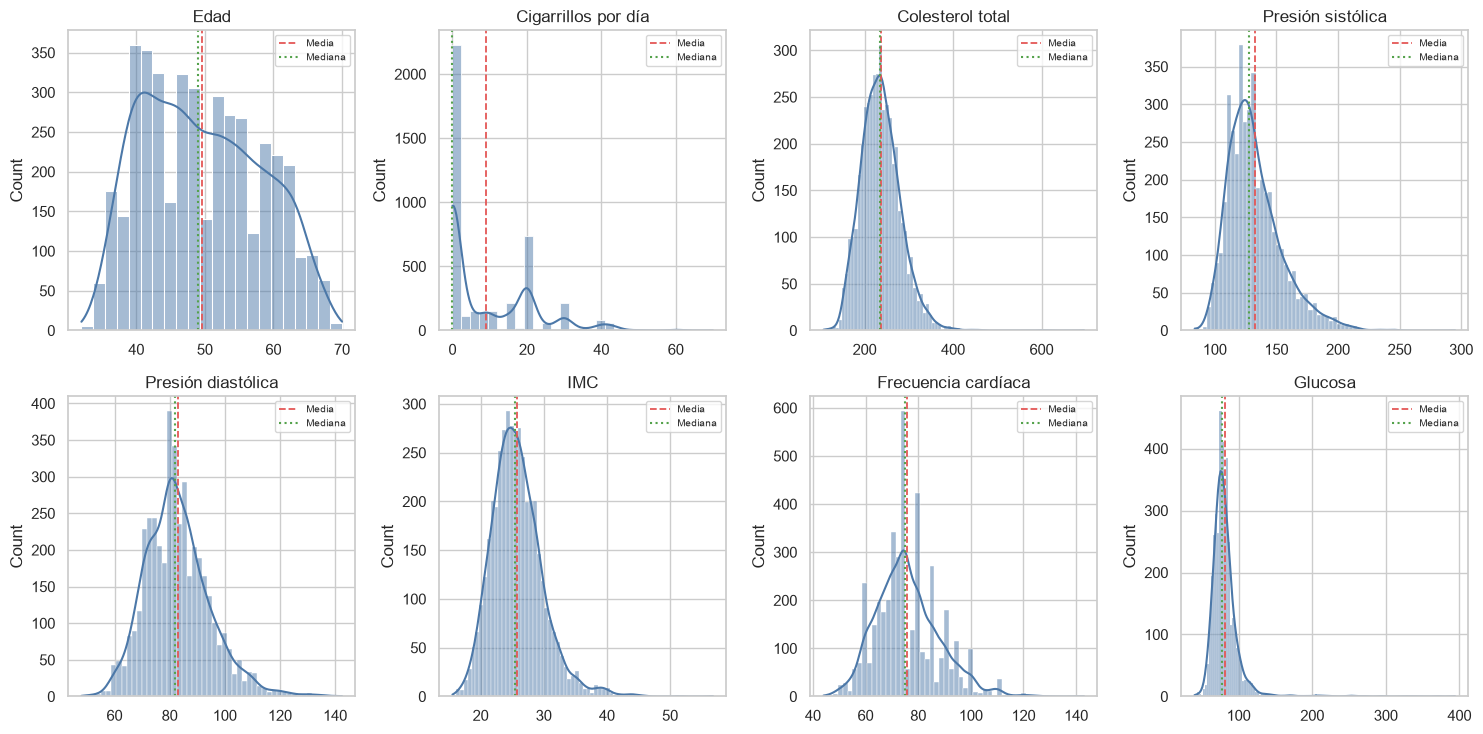

In [10]:
titulos = {
    "age": "Edad", "cigsPerDay": "Cigarrillos por día", "totChol": "Colesterol total",
    "sysBP": "Presión sistólica", "diaBP": "Presión diastólica", "BMI": "IMC",
    "heartRate": "Frecuencia cardíaca", "glucose": "Glucosa"
}

fig, axes = plt.subplots(2, 4, figsize=(15, 7.5))
for eje, variable in zip(axes.flat, variables_numericas):
    sns.histplot(df_analisis[variable], kde=True, ax=eje, color="#4C78A8")
    eje.axvline(df_analisis[variable].mean(), color="#E45756", linestyle="--", linewidth=1.3, label="Media")
    eje.axvline(df_analisis[variable].median(), color="#54A24B", linestyle=":", linewidth=1.5, label="Mediana")
    eje.set_title(titulos[variable])
    eje.set_xlabel("")
    eje.legend(fontsize=7)

plt.tight_layout()
plt.savefig(DIR_FIGURAS / "figura_2_distribuciones_numericas.png", dpi=300, bbox_inches="tight")
plt.show()

Las distribuciones de cigarrillos diarios y glucosa presentan asimetría positiva. En estas variables la
mediana y el rango intercuartílico complementan a la media y la desviación estándar. La presión sistólica
y el colesterol también muestran colas derechas y observaciones elevadas que deben considerarse al
interpretar los promedios.

### 2.5 Figura 3. Correlaciones entre variables numéricas

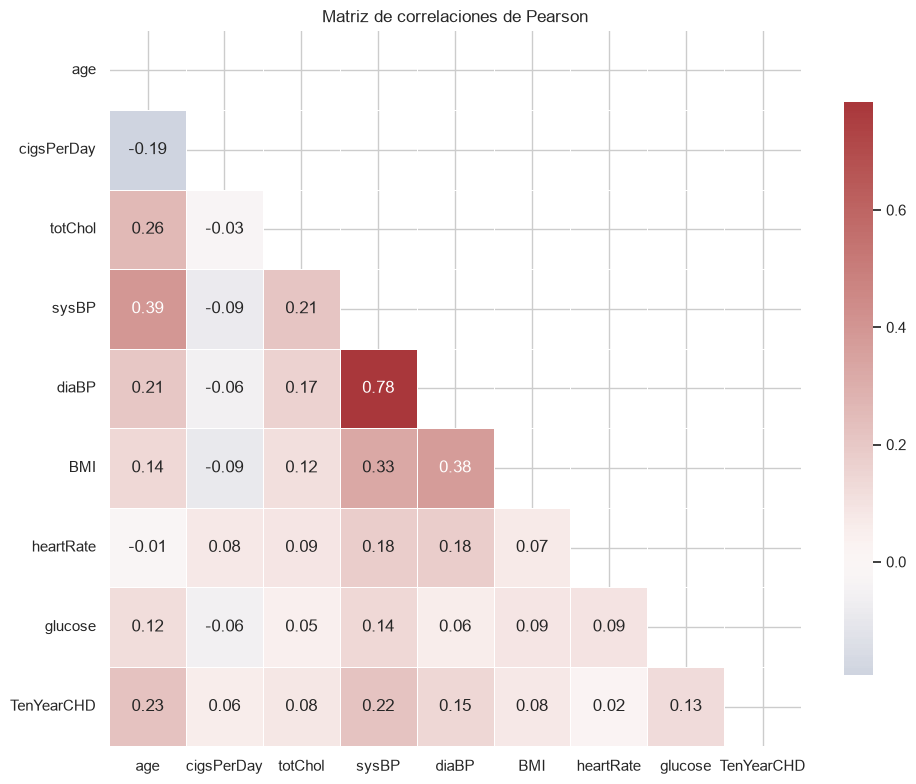

,r con TenYearCHD
age,0.225256
sysBP,0.216429
diaBP,0.145299
glucose,0.125544
totChol,0.082184
BMI,0.075192
cigsPerDay,0.057884
heartRate,0.022913


In [11]:
variables_correlacion = variables_numericas + ["TenYearCHD"]
correlaciones = df_analisis[variables_correlacion].corr(method="pearson")
mascara = np.triu(np.ones_like(correlaciones, dtype=bool))

plt.figure(figsize=(10, 8))
sns.heatmap(
    correlaciones, mask=mascara, cmap="vlag", center=0,
    annot=True, fmt=".2f", linewidths=0.5, cbar_kws={"shrink": 0.8}
)
plt.title("Matriz de correlaciones de Pearson")
plt.tight_layout()
plt.savefig(DIR_FIGURAS / "figura_3_correlaciones.png", dpi=300, bbox_inches="tight")
plt.show()

display(correlaciones["TenYearCHD"].drop("TenYearCHD").sort_values(key=abs, ascending=False).to_frame("r con TenYearCHD"))

La matriz permite identificar asociaciones lineales y posibles redundancias. La correlación no implica
causalidad y, al incluir una respuesta binaria, los coeficientes con `TenYearCHD` se interpretan como
correlaciones punto-biseriales. Las relaciones no lineales pueden no quedar representadas adecuadamente.

### 2.6 Figuras 4 y 5. Relaciones bivariadas con enfermedad coronaria

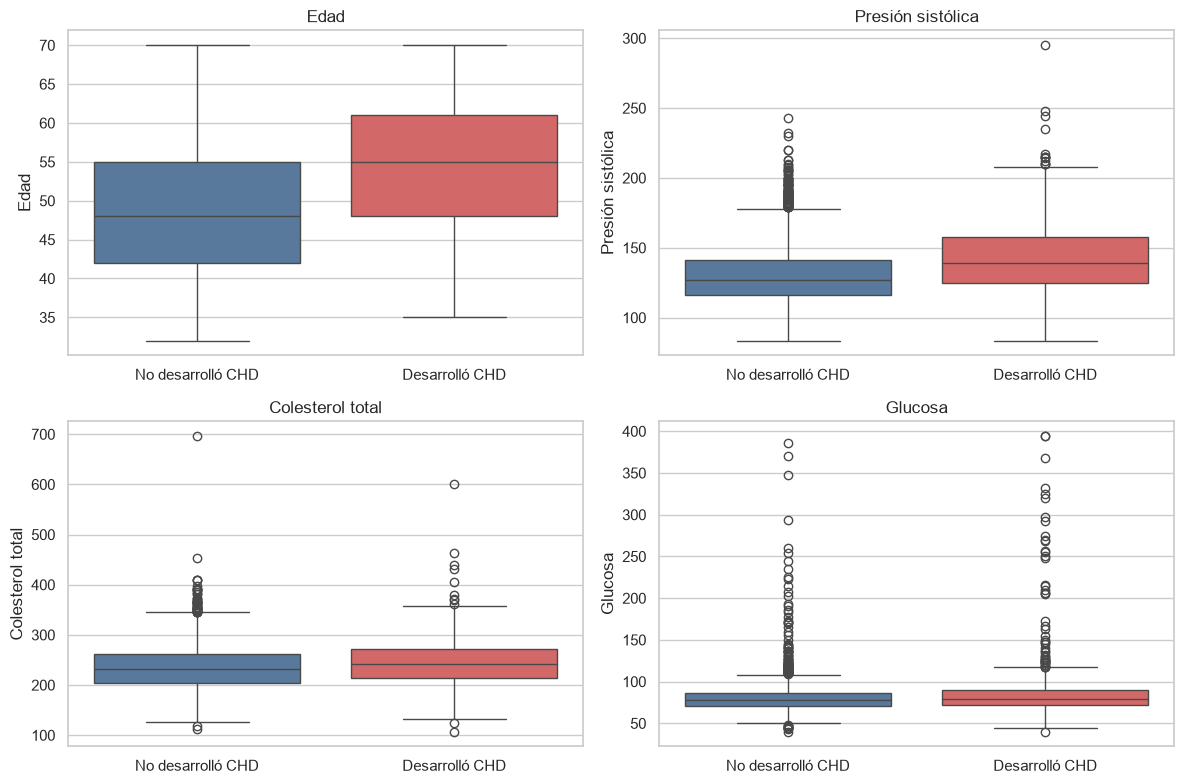

In [12]:
comparaciones = [
    ("age", "Edad"), ("sysBP", "Presión sistólica"),
    ("totChol", "Colesterol total"), ("glucose", "Glucosa")
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for eje, (variable, titulo) in zip(axes.flat, comparaciones):
    sns.boxplot(data=df_analisis, x="CHD_etiqueta", y=variable, hue="TenYearCHD",
                palette=PALETA, legend=False, ax=eje, showfliers=True)
    eje.set_title(titulo)
    eje.set_xlabel("")
    eje.set_ylabel(titulo)

plt.tight_layout()
plt.savefig(DIR_FIGURAS / "figura_4_variables_segun_chd.png", dpi=300, bbox_inches="tight")
plt.show()

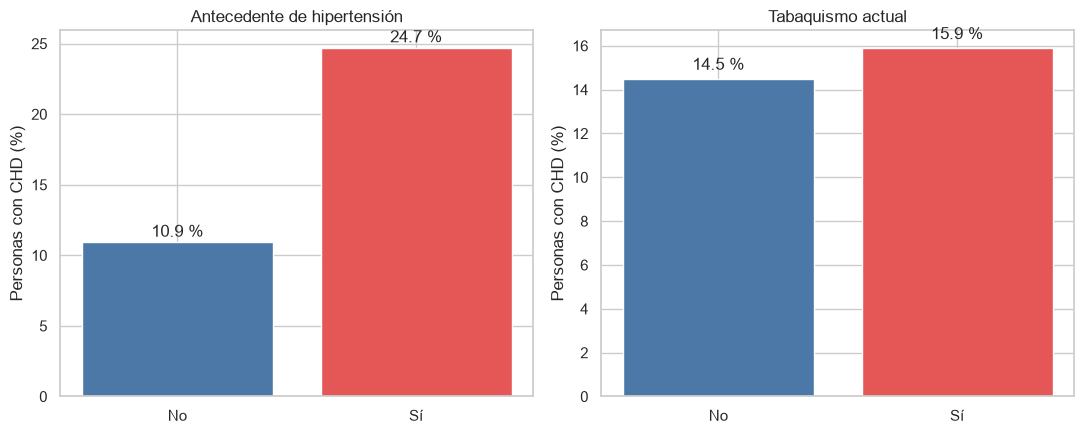

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

for eje, variable, titulo in [
    (axes[0], "prevalentHyp", "Antecedente de hipertensión"),
    (axes[1], "currentSmoker", "Tabaquismo actual"),
]:
    tasas = df_analisis.groupby(variable)["TenYearCHD"].agg(["mean", "count"])
    tasas["porcentaje"] = tasas["mean"] * 100
    barras = eje.bar([etiquetas_si_no[i] for i in tasas.index], tasas["porcentaje"],
                     color=["#4C78A8", "#E45756"])
    eje.set_title(titulo)
    eje.set_ylabel("Personas con CHD (%)")
    for barra, valor in zip(barras, tasas["porcentaje"]):
        eje.text(barra.get_x() + barra.get_width()/2, valor + 0.4, f"{valor:.1f} %", ha="center")

plt.tight_layout()
plt.savefig(DIR_FIGURAS / "figura_5_tasas_categoricas.png", dpi=300, bbox_inches="tight")
plt.show()

Los diagramas de caja permiten comparar posición, dispersión y valores extremos entre los grupos. Las
tasas categóricas muestran una diferencia visible según antecedente de hipertensión, mientras que la
comparación por tabaquismo actual requiere interpretarse junto con edad, intensidad y duración del consumo.
Estas relaciones son exploratorias y no constituyen evidencia causal.

## 3. Estimación de parámetros

Se estiman las medias poblacionales de edad, presión sistólica y colesterol total. Como la desviación
estándar poblacional es desconocida, se utiliza un intervalo bilateral basado en la distribución
**t de Student**. Además, se estima la proporción de enfermedad coronaria mediante el intervalo de Wilson.
En todos los casos se adopta un nivel de confianza del 95 %.

In [14]:
def intervalo_media_t(serie, confianza=0.95):
    x = pd.Series(serie).dropna().astype(float)
    n = len(x)
    media = x.mean()
    sd = x.std(ddof=1)
    ee = sd / np.sqrt(n)
    t_critico = stats.t.ppf(1 - (1 - confianza) / 2, df=n - 1)
    margen = t_critico * ee
    return {
        "n": n, "estimacion": media, "desviacion_estandar": sd,
        "error_estandar": ee, "limite_inferior": media - margen,
        "limite_superior": media + margen,
    }


seleccion_intervalos = {
    "Edad (años)": "age",
    "Presión sistólica (mmHg)": "sysBP",
    "Colesterol total (mg/dL)": "totChol",
}

resultados_ic = []
for nombre, variable in seleccion_intervalos.items():
    resultado = intervalo_media_t(df_analisis[variable])
    resultado["parametro"] = nombre
    resultados_ic.append(resultado)

tabla_ic_medias = pd.DataFrame(resultados_ic).set_index("parametro").round(2)
display(tabla_ic_medias)

,n,estimacion,desviacion_estandar,error_estandar,limite_inferior,limite_superior
parametro,,,,,,
Edad (años),4238,49.58,8.57,0.13,49.33,49.84
Presión sistólica (mmHg),4238,132.35,22.04,0.34,131.69,133.02
Colesterol total (mg/dL),4188,236.72,44.59,0.69,235.37,238.07


In [15]:
eventos = int(df_analisis["TenYearCHD"].sum())
n_total = int(df_analisis["TenYearCHD"].count())
proporcion = eventos / n_total
limite_inferior, limite_superior = proportion_confint(
    eventos, n_total, alpha=0.05, method="wilson"
)

tabla_ic_proporcion = pd.DataFrame({
    "eventos": [eventos],
    "n": [n_total],
    "estimacion": [proporcion],
    "limite_inferior": [limite_inferior],
    "limite_superior": [limite_superior],
}, index=["Proporción de CHD"])

display(tabla_ic_proporcion.round(4))
print(
    f"Proporción estimada: {proporcion*100:.2f} %; "
    f"IC 95 % de Wilson: [{limite_inferior*100:.2f} %, {limite_superior*100:.2f} %]."
)

,eventos,n,estimacion,limite_inferior,limite_superior
Proporción de CHD,644,4238,0.152,0.1415,0.1631


Proporción estimada: 15.20 %; IC 95 % de Wilson: [14.15 %, 16.31 %].


**Interpretación.** Cada intervalo representa un rango de valores compatibles con el parámetro poblacional
bajo los supuestos del procedimiento. No contiene al 95 % de las observaciones individuales ni representa
la probabilidad de que una persona específica desarrolle la enfermedad. La precisión depende del tamaño
muestral y de la representatividad de la muestra.

## 4. Pruebas de hipótesis

Se utiliza un nivel de significancia de $\alpha=0{,}05$. La significancia estadística se complementa con
intervalos de confianza y tamaños de efecto para evitar que la conclusión dependa únicamente del valor $p$.

### 4.1 Prueba t de Welch: presión sistólica según enfermedad coronaria

- $H_0$: la presión sistólica media es igual en los grupos con y sin enfermedad coronaria.
- $H_1$: la presión sistólica media difiere entre ambos grupos.

La variable es cuantitativa y los grupos son independientes. Se revisan tamaño, dispersión y asimetría.
Welch no exige igualdad de varianzas y es robusta con los tamaños muestrales disponibles.

In [16]:
sin_chd = df_analisis.loc[df_analisis["TenYearCHD"] == 0, "sysBP"].dropna()
con_chd = df_analisis.loc[df_analisis["TenYearCHD"] == 1, "sysBP"].dropna()

supuestos_welch = pd.DataFrame({
    "n": [len(sin_chd), len(con_chd)],
    "media": [sin_chd.mean(), con_chd.mean()],
    "desviacion_estandar": [sin_chd.std(ddof=1), con_chd.std(ddof=1)],
    "asimetria": [sin_chd.skew(), con_chd.skew()],
}, index=["Sin CHD", "Con CHD"]).round(3)
display(supuestos_welch)

t_welch, p_welch = stats.ttest_ind(con_chd, sin_chd, equal_var=False)
diferencia = con_chd.mean() - sin_chd.mean()

s1, s0 = con_chd.var(ddof=1), sin_chd.var(ddof=1)
n1, n0 = len(con_chd), len(sin_chd)
ee_diferencia = np.sqrt(s1/n1 + s0/n0)
gl_welch = (s1/n1 + s0/n0)**2 / ((s1/n1)**2/(n1-1) + (s0/n0)**2/(n0-1))
t_critico = stats.t.ppf(0.975, gl_welch)
ic_diferencia = (
    diferencia - t_critico * ee_diferencia,
    diferencia + t_critico * ee_diferencia,
)

sd_agrupada = np.sqrt(((n1-1)*s1 + (n0-1)*s0) / (n1+n0-2))
d_cohen = diferencia / sd_agrupada

print(f"t de Welch = {t_welch:.3f}; gl = {gl_welch:.1f}; p = {p_welch:.3e}")
print(f"Diferencia de medias = {diferencia:.2f} mmHg")
print(f"IC 95 % de la diferencia = [{ic_diferencia[0]:.2f}, {ic_diferencia[1]:.2f}] mmHg")
print(f"d de Cohen = {d_cohen:.3f}")
print("Decisión:", "rechazar H0" if p_welch < 0.05 else "no rechazar H0")

,n,media,desviacion_estandar,asimetria
Sin CHD,3594,130.334,20.455,1.057
Con CHD,644,143.619,26.690,0.999


t de Welch = 12.015; gl = 783.9; p = 1.210e-30
Diferencia de medias = 13.29 mmHg
IC 95 % de la diferencia = [11.11, 15.46] mmHg
d de Cohen = 0.617
Decisión: rechazar H0


La prueba evalúa una diferencia no ajustada entre grupos. Un resultado significativo no demuestra que la
presión sistólica cause la enfermedad, porque otras variables —como edad, sexo, tabaquismo o diabetes—
pueden actuar como factores de confusión.

### 4.2 Chi-cuadrado: hipertensión previa y enfermedad coronaria

- $H_0$: el antecedente de hipertensión y la enfermedad coronaria a diez años son independientes.
- $H_1$: existe asociación entre ambas variables.

Ambas variables son categóricas. Se verifica que todas las frecuencias esperadas sean al menos 5. La
intensidad de la asociación se resume con $V$ de Cramér y se complementa con riesgo relativo y *odds ratio*.

In [17]:
tabla_contingencia = pd.crosstab(
    df_analisis["prevalentHyp"],
    df_analisis["TenYearCHD"]
).rename(index=etiquetas_si_no, columns=etiquetas_si_no)

display(tabla_contingencia)

chi2, p_chi2, gl_chi2, esperadas = stats.chi2_contingency(tabla_contingencia)
n_chi2 = tabla_contingencia.to_numpy().sum()
v_cramer = np.sqrt(chi2 / (n_chi2 * min(tabla_contingencia.shape[0]-1, tabla_contingencia.shape[1]-1)))

a = tabla_contingencia.loc["Sí", "Sí"]
b = tabla_contingencia.loc["Sí", "No"]
c = tabla_contingencia.loc["No", "Sí"]
d = tabla_contingencia.loc["No", "No"]

riesgo_hipertension = a / (a + b)
riesgo_sin_hipertension = c / (c + d)
riesgo_relativo = riesgo_hipertension / riesgo_sin_hipertension
odds_ratio = (a * d) / (b * c)

print(f"Frecuencia esperada mínima = {esperadas.min():.2f}")
print(f"Chi-cuadrado = {chi2:.3f}; gl = {gl_chi2}; p = {p_chi2:.3e}")
print(f"V de Cramér = {v_cramer:.3f}")
print(f"Riesgo con hipertensión = {riesgo_hipertension*100:.2f} %")
print(f"Riesgo sin hipertensión = {riesgo_sin_hipertension*100:.2f} %")
print(f"Riesgo relativo = {riesgo_relativo:.2f}")
print(f"Odds ratio = {odds_ratio:.2f}")
print("Decisión:", "rechazar H0" if p_chi2 < 0.05 else "no rechazar H0")

TenYearCHD,No,Sí
prevalentHyp,,
No,2603,319
Sí,991,325


Frecuencia esperada mínima = 199.98
Chi-cuadrado = 132.611; gl = 1; p = 1.100e-30
V de Cramér = 0.177
Riesgo con hipertensión = 24.70 %
Riesgo sin hipertensión = 10.92 %
Riesgo relativo = 2.26
Odds ratio = 2.68
Decisión: rechazar H0


La prueba chi-cuadrado identifica asociación, no causalidad. El riesgo relativo comunica cuántas veces es
mayor la proporción observada de enfermedad en personas con antecedente de hipertensión; el *odds ratio*
compara las razones de probabilidades y no debe interpretarse directamente como riesgo relativo.

## 5. Síntesis, limitaciones y próximos pasos

El análisis caracteriza una muestra de 4.238 personas y cuantifica la incertidumbre de parámetros clínicos
relevantes. Las comparaciones bivariadas sugieren diferencias en edad y presión sistólica, además de una
asociación entre hipertensión previa y enfermedad coronaria. Las conclusiones se limitan a asociaciones no
ajustadas dentro de una base observacional.

Las principales limitaciones son la presencia de datos ausentes, el desbalance de la respuesta, la posible
existencia de factores de confusión y la falta de información suficiente para asegurar representatividad
fuera de la población del estudio. En las fases siguientes se evaluará el tratamiento de faltantes y el
aporte conjunto de las variables mediante modelos multivariados, manteniendo separadas las tareas de
explicación, predicción y evaluación causal.

## 6. Verificación de reproducibilidad

In [18]:
figuras_esperadas = [
    "figura_1_objetivo_faltantes.png",
    "figura_2_distribuciones_numericas.png",
    "figura_3_correlaciones.png",
    "figura_4_variables_segun_chd.png",
    "figura_5_tasas_categoricas.png",
]

assert RUTA_DATOS.exists(), "No se encontró el dataset."
assert df.shape == (4238, 16), "Las dimensiones del dataset no coinciden con las esperadas."
assert duplicados == 0, "Se detectaron filas duplicadas."
assert reporte_inconsistencias["cantidad"].sum() == 0, "Existen inconsistencias de codificación."
assert all((DIR_FIGURAS / nombre).exists() for nombre in figuras_esperadas), "Faltan figuras exportadas."

print("Validación completada:")
print("- dataset localizado y dimensiones verificadas")
print("- ausencia de duplicados e inconsistencias de codificación")
print("- cinco figuras exportadas")
print("- notebook listo para Restart Kernel and Run All Cells")

Validación completada:
- dataset localizado y dimensiones verificadas
- ausencia de duplicados e inconsistencias de codificación
- cinco figuras exportadas
- notebook listo para Restart Kernel and Run All Cells
